In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path

from magnetron.parameters import (
    GeometryParameters,
    MeshSettings,
    ElectrostaticParameters
)
from magnetron.geometry import MagnetronGeometry
from magnetron.mesh import MagnetronMesh

from magnetron.electrostatic import ElectrostaticSimulation  

In [4]:
results_dir = Path("../results/experiment")

geometry_parameters = GeometryParameters(
    target_diameter=50.8,
    target_thickness=3.0,
    magnet_height=10.0,
    inner_magnet_diameter=15.0,
    outer_magnet_diameter=8.0,
    outer_magnet_ring_radius=18.0,
    magnet_to_target_distance=5.0,
)

geometry = MagnetronGeometry(geometry_parameters)

mesh_path = MagnetronMesh(
    geometry,
    MeshSettings(min_size=0.025, max_size=0.5),
).generate(results_dir / "mesh.msh")

Info    : Meshing 1D...nts - Adding holes                                                                                              
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 19 (Line)
Info    : [ 10%] Meshing curve 23 (Line)
Info    : [ 20%] Meshing curve 24 (Line)
Info    : [ 20%] Meshing curve 25 (Line)
Info    : [ 20%] Meshing curve 26 (Line)
Info    : [ 30%] Meshing curve 27 (Line)
Info    : [ 30%] Meshing curve 28 (Line)
Info    : [ 40%] Meshing curve 29 (Line)
Info    : [ 40%] Meshing curve 30 (Line)
Info    : [ 40%] Meshing curve 31 (Line)
Info    : [ 50%] Meshing curve 32 (Line)
Info    : [ 50%] Meshing curve 33 (Line)
Info    : [ 60%] Meshing curve 34 (Line)
Info    : [ 60%] Meshing curve 35 (Line)
Info    : [ 60%] Meshing curve 36 (Line)
Info    : [ 70%] Meshing curve 37 (Line)
Info    : [ 70%] Meshing curve 38 (Line)
Info    : [ 70%] Meshing curve 39 (Line)
Info    : [ 80%] Meshing curve 40 (Line)
Info    : [ 80%] Meshing curve 41 (Line)
Inf

In [5]:
electrostatic_parameters = ElectrostaticParameters(target_voltage=-400.0, ground_voltage=0.0, eps_r_air=1.0)

electrostatic_result = ElectrostaticSimulation(mesh_path, electrostatic_parameters).solve(results_dir)

print(electrostatic_result.fields_file)
print(electrostatic_result.metadata_file)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 54 entities
Info    : 22897 nodes
Info    : 45232 elements
Info    : Done reading '../results/experiment/mesh.msh'


ld: warning: duplicate -rpath '/Users/jakub/miniconda3/envs/magnetron/lib' ignored
ld: warning: duplicate -rpath '/Users/jakub/miniconda3/envs/magnetron/lib' ignored
ld: warning: duplicate -rpath '/Users/jakub/miniconda3/envs/magnetron/lib' ignored
ld: warning: duplicate -rpath '/Users/jakub/miniconda3/envs/magnetron/lib' ignored


../results/experiment/electrostatic_fields.xdmf
../results/experiment/electrostatic_metadata.json


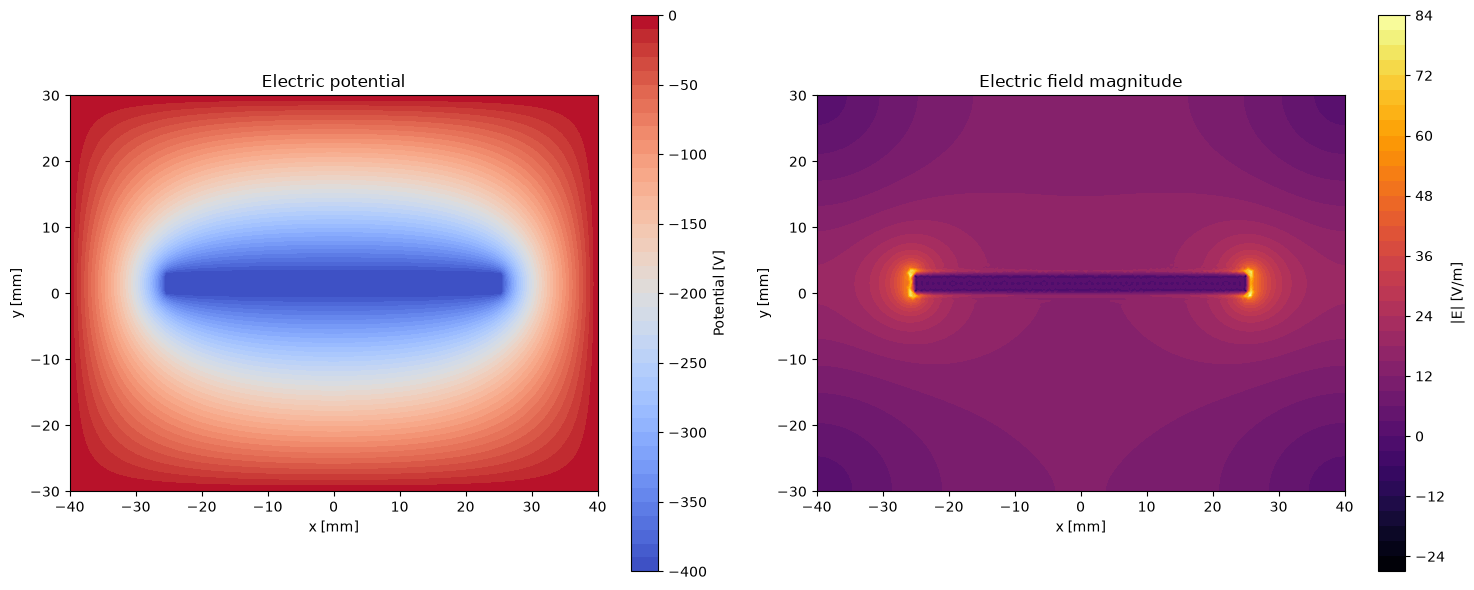

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.tri as mtri
from dolfinx import plot as dolfinx_plot

domain = electrostatic_result.domain

topology, cell_types, geometry = dolfinx_plot.vtk_mesh(
    domain, domain.topology.dim
)
triangles = topology.reshape(-1, 4)[:, 1:]
points = domain.geometry.x[:, :2]

triangulation = mtri.Triangulation(
    points[:, 0],
    points[:, 1],
    triangles,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

potential = electrostatic_result.potential.x.array
plot1 = axes[0].tricontourf(
    triangulation, potential, levels=40, cmap="coolwarm"
)
fig.colorbar(plot1, ax=axes[0], label="Potential [V]")
axes[0].set_title("Electric potential")
axes[0].set_xlabel("x [mm]")
axes[0].set_ylabel("y [mm]")
axes[0].set_aspect("equal")

e_magnitude = electrostatic_result.e_magnitude.x.array
plot2 = axes[1].tricontourf(
    triangulation, e_magnitude, levels=40, cmap="inferno"
)
fig.colorbar(plot2, ax=axes[1], label="|E| [V/m]")
axes[1].set_title("Electric field magnitude")
axes[1].set_xlabel("x [mm]")
axes[1].set_ylabel("y [mm]")
axes[1].set_aspect("equal")

plt.tight_layout()
plt.show()